# Teknoloji Etiketleri Ağının Evrimi
2015 ve 2025, 6–9 Ocak UTC. Yalnızca Stack Exchange API. Bu defter ham önbellekten gerçek işleme, tam analizi ve teslim üretimini çalıştırır. İlk çevrimiçi veri toplama: `python scripts/collect.py`. Kullanıcı alanları kaynak filtrede dışlanır.

**Kapsam:** yıllık temsili örneklem değil; bugün erişilebilen soruların güncel etiketleri.

In [1]:
from pathlib import Path
import sys, json, pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'scripts').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
import process, analyze, build_artifacts
print('Workspace:',ROOT)

Workspace: C:\Users\Admin\Desktop\Yeni klasör


## 1. Ham veriden ağa ve zorunlu ara kontrol
Her soruda tekilleştirilmiş sırasız çiftler, minimum ağırlık 1, izole düğümler dahil. CSV ve GraphML eşitliği ve her iki yılda en az 500 düğüm geçmeden ileri analiz yapılmaz.

In [2]:
process.main()
display(pd.read_csv(ROOT/'data/processed/checkpoint.csv'))

{'year': 2015, 'questions': 18922, 'nodes': 7693, 'edges': 37771, 'density': 0.0012765959747970056, 'components': 144, 'isolates': 108, 'duplicates': 0, 'invalid': 0, 'raw_pages': 196}


{'year': 2025, 'questions': 2070, 'nodes': 2478, 'edges': 6815, 'density': 0.002220590856379091, 'components': 112, 'isolates': 41, 'duplicates': 0, 'invalid': 0, 'raw_pages': 26}


,year,questions,nodes,edges,density,components,isolates,duplicates,invalid,raw_pages
0,2015,18922,7693,37771,0.001277,144,108,0,0,196
1,2025,2070,2478,6815,0.002221,112,41,0,0,26


## 2. Aynı tanımlarla tam analiz
Ağırlıksız derece, tam betweenness, Wasserman–Faust düzeltmeli tam closeness; ağırlıklı PageRank (0,85). EBB üzerinde tam ortalama yol ve çap. Louvain ve Leiden ağırlıklı modülerlik γ=1, seed=110…119. Her grupta 45 NMI çifti. powerlaw ayrık uyum, lognormal ve üstel alternatifleri.

**Null:** Yıl başına 100 basit, derece koruyan yeniden bağlama. 10m deneme; seed=10000+yıl+tekrar. Null karşılaştırması ağırlıksız. Yol için EBB’den 128 kaynak, seed=610.

**İleri yöntem:** Jaccard + Hungarian (0,10 eşiği), ortak etiket akışları; güç temelli $P_i=1-\sum_c(s_{ic}/s_i)^2$. Köprü adayları için k≥10 ve s≥20.

In [3]:
analyze.main()
metrics=json.loads((ROOT/'results/metrics.json').read_text(encoding='utf-8'))
display(pd.DataFrame(metrics).drop(index='powerlaw'))
display(pd.DataFrame({y:v['powerlaw'] for y,v in metrics.items()}))

centralities 2015


null models 2015


null 2015 0


null 2015 20


null 2015 40


...

null 2025 40


null 2025 60


null 2025 80


,2015,2025
nodes,7693,2478
edges,37771,6815
density,0.001277,0.002221
components,144,112
lcc_nodes,7500,2241
clustering,0.681004,0.713595
assortativity,-0.173687,-0.148334
average_path_exact,3.081545,3.59115
diameter_exact,8,9
path_sample,3.060983,3.592861


,2015,2025
alpha,2.113366e+00,2.437519e+00
xmin,6.000000e+00,6.000000e+00
D,1.627854e-02,1.755645e-02
tail_n,2.506000e+03,4.950000e+02
vs_lognormal_R,-2.047942e+00,-2.864678e-01
vs_lognormal_p,4.056565e-02,7.745199e-01
vs_exponential_R,8.210156e+00,5.287813e+00
vs_exponential_p,2.209017e-16,1.237873e-07


2015


,tag,degree_centrality
0,java,0.178887
1,c#,0.137415
2,javascript,0.135465
3,android,0.130395
4,python,0.110114
5,php,0.101924
6,c++,0.084633
7,ios,0.078783
8,html,0.075013
9,jquery,0.068383


,tag,betweenness
0,java,0.169182
1,c#,0.114794
2,android,0.106103
3,javascript,0.097519
4,python,0.095266
5,php,0.067662
6,c++,0.066692
7,ios,0.059151
8,html,0.036021
9,jquery,0.029310


,tag,closeness
0,java,0.513871
1,javascript,0.490759
2,c#,0.487617
3,python,0.484868
4,android,0.482659
5,php,0.474638
6,html,0.471759
7,c++,0.465748
8,mysql,0.461981
9,ios,0.457442


,tag,pagerank
0,java,0.027318
1,javascript,0.025929
2,c#,0.019704
3,android,0.019700
4,php,0.017047
5,python,0.014649
6,jquery,0.014294
7,html,0.013895
8,ios,0.011802
9,c++,0.010742


,degree_centrality,betweenness,closeness,pagerank
degree_centrality,1.000000,0.850637,0.685036,0.884430
betweenness,0.850637,1.000000,0.615121,0.824268
closeness,0.685036,0.615121,1.000000,0.514980
pagerank,0.884430,0.824268,0.514980,1.000000


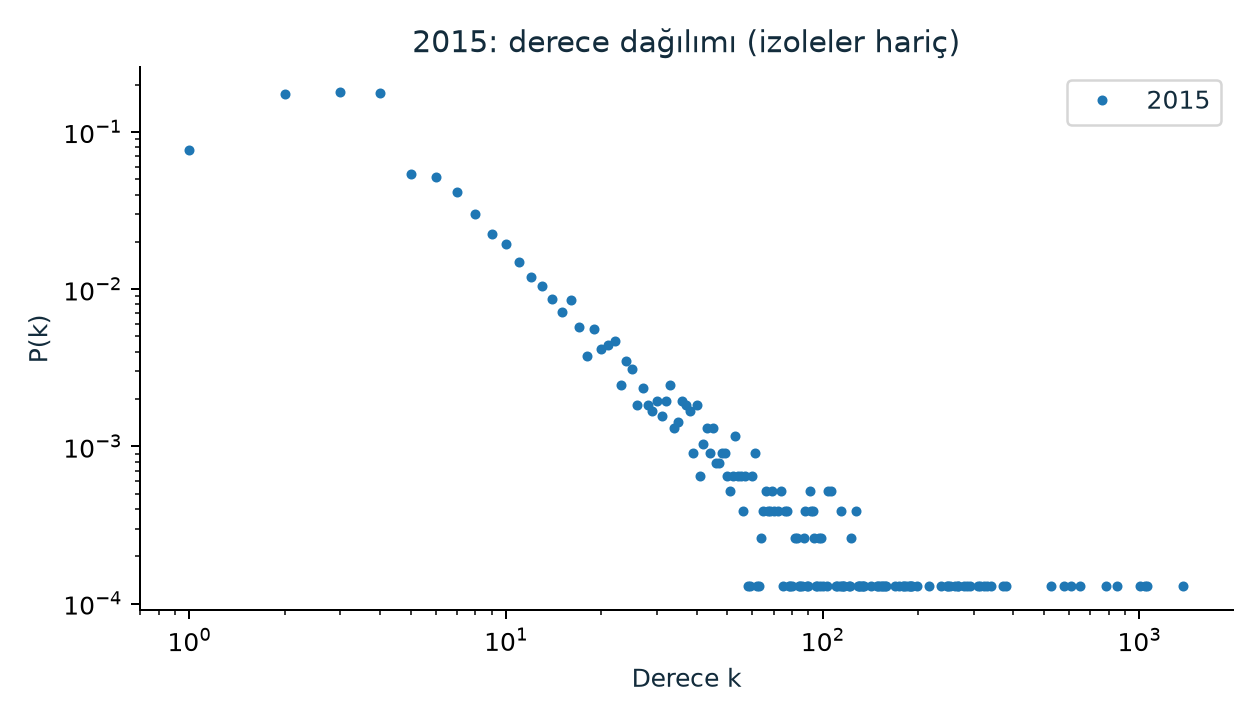

2025


,tag,degree_centrality
0,python,0.130803
1,javascript,0.091239
2,java,0.074687
3,c#,0.072265
4,c++,0.062172
5,android,0.053694
6,reactjs,0.042390
7,azure,0.041986
8,html,0.039160
9,flutter,0.036738


,tag,betweenness
0,python,0.216564
1,javascript,0.136327
2,c#,0.087159
3,java,0.085942
4,c++,0.078528
5,azure,0.073680
6,android,0.073466
7,r,0.038200
8,node.js,0.036817
9,angular,0.036449


,tag,closeness
0,python,0.404327
1,javascript,0.394561
2,azure,0.367236
3,android,0.366705
4,java,0.359099
5,c#,0.358210
6,arrays,0.357199
7,html,0.353090
8,performance,0.352292
9,c++,0.351985


,tag,pagerank
0,python,0.025956
1,javascript,0.017365
2,java,0.013626
3,c#,0.013550
4,c++,0.010596
5,android,0.010074
6,reactjs,0.007616
7,html,0.007456
8,flutter,0.007068
9,azure,0.007032


,degree_centrality,betweenness,closeness,pagerank
degree_centrality,1.000000,0.739528,0.611193,0.755106
betweenness,0.739528,1.000000,0.506586,0.701048
closeness,0.611193,0.506586,1.000000,0.248668
pagerank,0.755106,0.701048,0.248668,1.000000


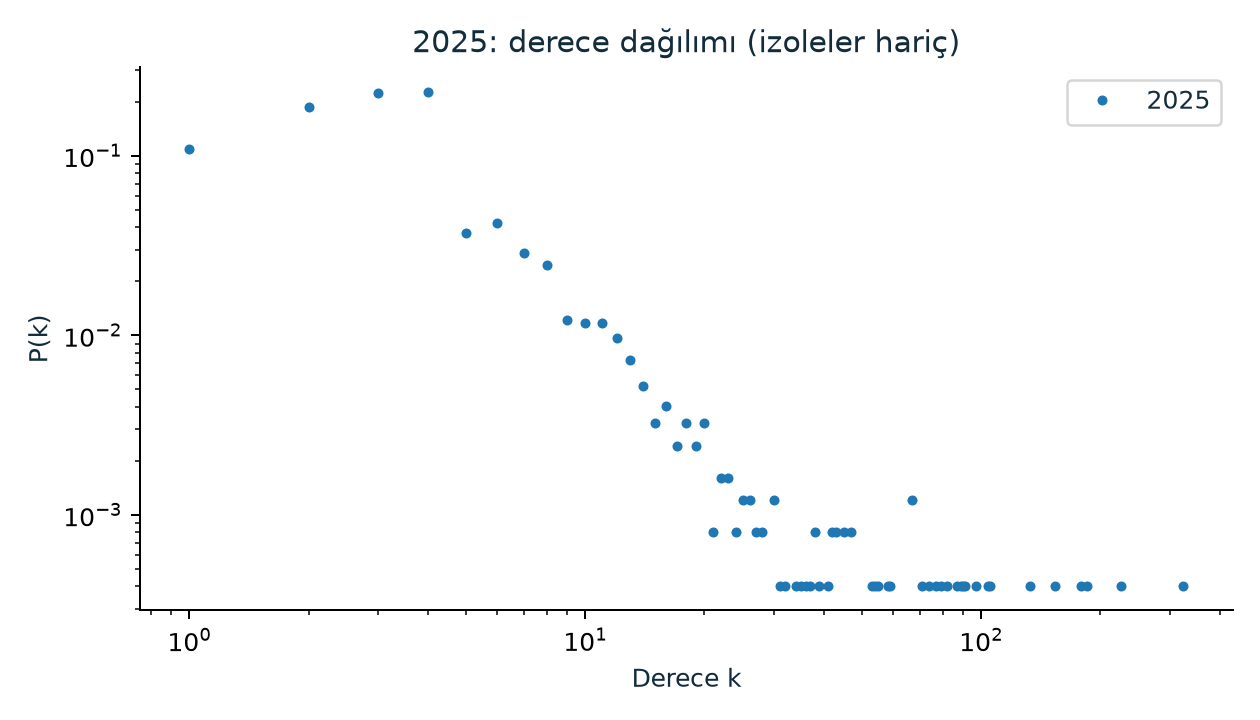

In [4]:
for year in [2015,2025]:
    print(year)
    for metric in ['degree_centrality','betweenness','closeness','pagerank']:
        display(pd.read_csv(ROOT/f'results/top10_{metric}_{year}.csv')[['tag',metric]])
    display(pd.read_csv(ROOT/f'results/spearman_{year}.csv',index_col=0))
    display(Image(filename=str(ROOT/f'results/degree_{year}.png')))

In [5]:
display(pd.read_csv(ROOT/'results/community_stability.csv'))
for year in [2015,2025]:
    display(pd.read_csv(ROOT/f'results/null_summary_{year}.csv'))
    display(pd.read_csv(ROOT/f'results/bridges_{year}.csv').head(10))
display(pd.read_csv(ROOT/'results/community_matching.csv').query('accepted == True'))
display(pd.read_csv(ROOT/'results/edge_changes.csv').head(10))

,year,algorithm,nmi_mean,nmi_min,nmi_sd,modularity_mean,modularity_max,pairs
0,2015,Louvain,0.781624,0.728838,0.026359,0.529564,0.530673,45
1,2015,Leiden,0.870376,0.774298,0.040303,0.533308,0.534600,45
2,2025,Louvain,0.890677,0.816283,0.027137,0.696178,0.698313,45
3,2025,Leiden,0.930462,0.885982,0.023009,0.701361,0.702421,45


,year,metric,observed,null_mean,null_sd,z,p_upper,p_lower
0,2015,clustering,0.681004,0.159263,0.002118,246.341836,0.009901,1.000000
1,2015,path,3.060983,3.090744,0.030694,-0.969595,0.841584,0.168317
2,2015,modularity,0.470100,0.249159,0.001092,202.313755,0.009901,1.000000


,tag,degree,strength,degree_centrality,betweenness,closeness,pagerank,community,participation,bridge_eligible
0,performance,148,247.0,0.019241,0.006348,0.443673,0.001507,2,0.879083,True
1,text,53,64.0,0.006890,0.001060,0.398281,0.000413,4,0.872070,True
2,printing,48,60.0,0.006240,0.000841,0.416715,0.000356,3,0.871667,True
3,error-handling,42,53.0,0.005460,0.000669,0.409870,0.000322,10,0.867925,True
4,regex,158,415.0,0.020541,0.008931,0.448656,0.002452,7,0.864183,True
5,view,45,56.0,0.005850,0.001525,0.400462,0.000370,5,0.864158,True
6,server,86,128.0,0.011180,0.001693,0.423817,0.000756,0,0.860229,True
7,calendar,26,40.0,0.003380,0.000376,0.390871,0.000255,5,0.856250,True
8,integer,31,35.0,0.004030,0.000478,0.402890,0.000216,2,0.855510,True
9,replace,32,47.0,0.004160,0.000160,0.364013,0.000274,6,0.854685,True


,year,metric,observed,null_mean,null_sd,z,p_upper,p_lower
0,2025,clustering,0.713595,0.060176,0.002884,226.549183,0.009901,1.000000
1,2025,path,3.592861,3.548130,0.039969,1.119125,0.168317,0.841584
2,2025,modularity,0.668395,0.398967,0.001723,156.366986,0.009901,1.000000


,tag,degree,strength,degree_centrality,betweenness,closeness,pagerank,community,participation,bridge_eligible
0,http,19,20.0,0.007671,0.002870,0.309784,0.000910,5,0.850000,True
1,performance,35,40.0,0.014130,0.010284,0.352292,0.001849,2,0.815000,True
2,unit-testing,30,33.0,0.012111,0.013311,0.350827,0.001470,15,0.811754,True
3,arrays,31,31.0,0.012515,0.013319,0.357199,0.001492,2,0.763788,True
4,macos,20,21.0,0.008074,0.006646,0.315526,0.001027,12,0.761905,True
5,database,23,26.0,0.009285,0.003922,0.327408,0.001160,1,0.742604,True
6,postgresql,67,85.0,0.027049,0.029408,0.340851,0.004159,7,0.734948,True
7,json,43,49.0,0.017360,0.019323,0.344327,0.002464,8,0.731362,True
8,docker,47,58.0,0.018975,0.018670,0.335710,0.002836,12,0.721165,True
9,go,24,25.0,0.009689,0.007408,0.286842,0.001403,9,0.684800,True


,source,target,jaccard,jaccard_all_tags,overlap,hungarian_selected,accepted,source_shared_fraction,target_shared_fraction
5,0,5,0.318182,0.060345,63,True,True,0.398734,0.611650
132,1,0,0.363184,0.061448,73,True,True,0.565891,0.503448
266,2,2,0.286275,0.069458,73,True,True,0.421965,0.470968
399,3,3,0.324873,0.061538,64,True,True,0.453901,0.533333
529,4,1,0.248889,0.059957,56,True,True,0.386207,0.411765
804,6,12,0.150442,0.026439,17,True,True,0.171717,0.548387
930,7,6,0.207547,0.035200,22,True,True,0.265060,0.488889
1060,8,4,0.241135,0.046196,34,True,True,0.539683,0.303571
1195,9,7,0.255102,0.054945,25,True,True,0.328947,0.531915
1335,10,15,0.125000,0.021108,8,True,True,0.181818,0.285714


,source,target,weight_2015,weight_2025,per1000_2015,per1000_2025,delta_per1000
0,java,spring-boot,9,31,0.475637,14.975845,14.500209
1,dart,flutter,0,29,0.000000,14.009662,14.009662
2,javascript,reactjs,10,19,0.528485,9.178744,8.650259
3,spring,spring-boot,16,19,0.845577,9.178744,8.333167
4,next.js,reactjs,0,14,0.000000,6.763285,6.763285
5,android,kotlin,0,14,0.000000,6.763285,6.763285
6,asp.net-core,c#,1,14,0.052849,6.763285,6.710436
7,android,flutter,0,13,0.000000,6.280193,6.280193
8,expo,react-native,0,13,0.000000,6.280193,6.280193
9,pandas,python,42,17,2.219639,8.212560,5.992922


## 3. Görseller ve teslim dosyaları
Statik ve etkileşimli görseller 350 düğüm alt kümesi gösterir; bütün metrikler tam ağdandır. Sankey yalnızca iki yılda da gözlenen etiketleri sayar. Yeni ve yok görünen etiketler ayrı tutulur.

Artifacts generated


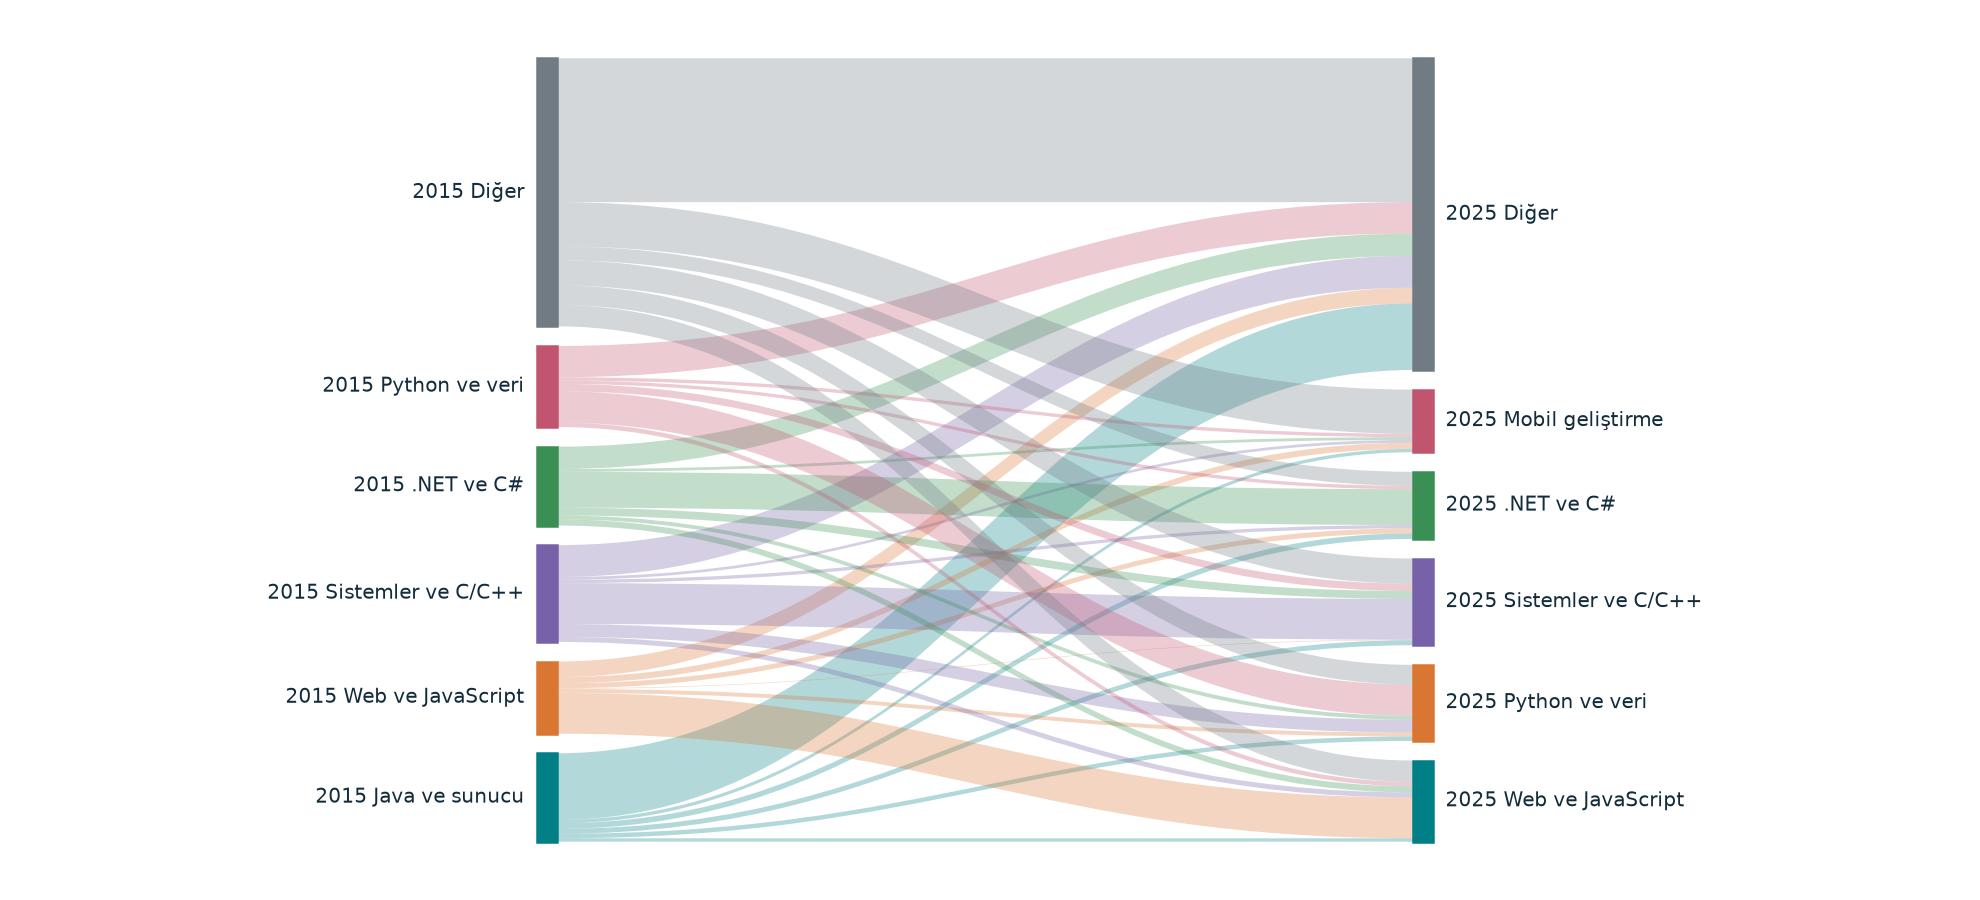

Bu iki 72 saatlik kesitte en güçlü etiketler 2015’te javascript, java, c#, 2025’te python, javascript, java oldu. 1225 ortak etiketin topluluk benzerliği NMI=0,298 düzeyindeydi. Hacim eşiğini geçen yüksek katılımlı köprü adayları 2015’te performance, text, printing, 2025’te http, performance, unit-testing olarak öne çıktı. Bu bulgular teknoloji kullanımının neden değiştiğini değil, Stack Overflow’da seçili günlerde etiketlerin nasıl birlikte kullanıldığını gösterir.


In [2]:
build_artifacts.main()
display(Image(filename=str(ROOT/'results/sankey.png')))
print((ROOT/'results/conclusion.txt').read_text(encoding='utf-8'))

## 4. Yorumlama sınırları
Silinme, yeniden etiketleme, hafta günü ve soru hacmi etkileri vardır. Kenar farklarında 1.000 soru başına sıklık kullanılır. Null model projeksiyon kliklerini ve güçleri korumaz; karışımı garanti edilmez. Log-log grafik ve dağılım karşılaştırması tek başına güç yasası kanıtı değildir. Nedensellik iddiası yapılmaz. Kaynaklar, tüm somut ölçü yorumları ve lisans ayrıntıları PDF raporunda ve veri sözlüğündedir.